This notebook is made in order to understand how the data looks like.

In [1]:
# Necessary packages
import pandas as pd
import warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#Ignore warnings
warnings.filterwarnings('ignore')

In [2]:
# Loading in the data first
df = pd.read_csv("P1_2627_C1_Answers_Anon.csv", on_bad_lines='skip')
df.head()

,Student number (sorted),MC points,39,40,41,42,43,44,45,46,47
0,1,38.0000,A,D,B,C,EADI,e,C,5.0,30
1,2,32.0375,A,E,A,B,A,e,C,6.0,NaN
2,3,32.2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,30.2000,A,C,A,B,FABJ,e,e,7.0,10
4,5,40.2000,A,D,A,C,FAHIJ,e,D,4.0,15


In [3]:
df_no_consent = df[df['39'].isna()]
df = df[df['39']=='A']

In [4]:
print(df.shape,df_no_consent.shape)

(182, 11) (67, 11)


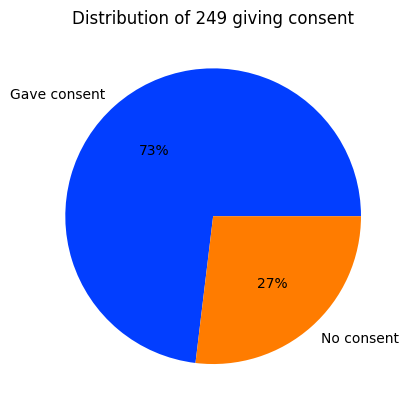

In [5]:
# Data and Labels
data = [df.shape[0],df_no_consent.shape[0]]
labels = ["Gave consent","No consent"]
# Colors
colors = sns.color_palette('bright') 

#Plotting pie chart
plt.pie(data, labels=labels, colors=colors, autopct='%.0f%%')
plt.title(f"Distribution of {data[0]+data[1]} giving consent")
plt.show()

Around 75% of the students filled in the survey and gave consent for it after finishing the programming 1 exam. We will only consider people who gave consent on using their data and leave the rest out.

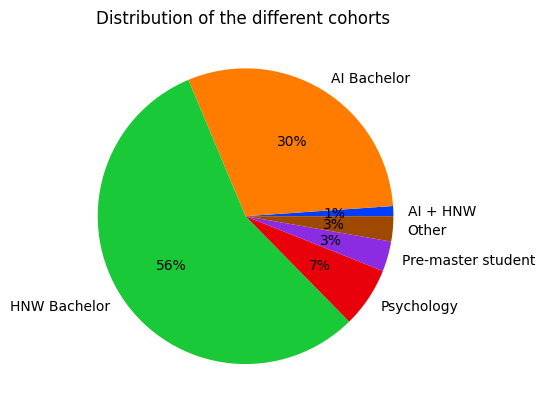

In [6]:
# Data and labels
label_names = ["AI + HNW","AI Bachelor","HNW Bachelor","Psychology","Pre-master student","Other"]
labels = ["AB","A","B","C","D","E"]
data = [df[df['40']==label].shape[0] for label in labels]

# Plotting pie char
plt.pie(data, labels=label_names, colors=colors, autopct='%.0f%%')
plt.title("Distribution of the different cohorts ")
plt.show()

More than half of the students who filled in the survey are part of the human neuroscience program, while around 30% follow the AI bachelor.

In [7]:
names = ["Pre-master student","Other","Psychology","HNW Bachelor","AI Bachelor","AI + HNW"]
label_mapping = dict(zip(df['40'].unique(),names))

# Map labels for nice labels in visualizaiton
df['40']= df['40'].map(label_mapping)

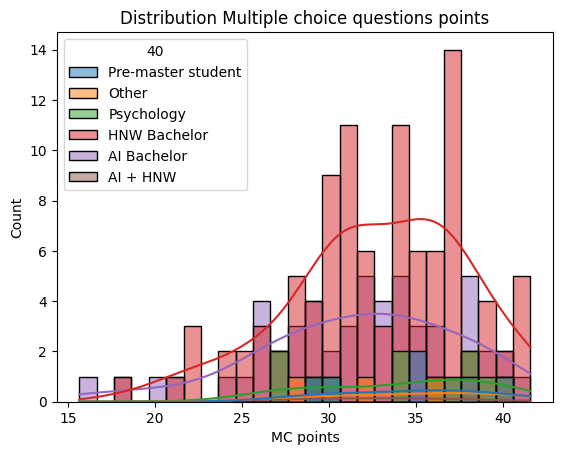

In [8]:
# Distribution points
sns.histplot(data=df,x="MC points",binwidth=1,kde=True,hue="40")
plt.title("Distribution Multiple choice questions points")
plt.show()

True the kernel density estimator we can see that the AI Bachelor cohort has a normal distrubtion. The HNW bachelor cohort seems to have two two normal distributions or one with two bumps

In [9]:
# Distribution Learning Strategies